<a href="https://colab.research.google.com/github/pdtarricone/analytics_portfolio/blob/PDT_Analytics_Portfolio/Projecct_1_Wind_Turbine_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problem Statement
Business Context
Aeolus Renewables is an independent power producer operating a fleet of 1,150 onshore wind turbines (2.5 MW class) across 16 wind farms in the central plains region, with a combined installed capacity of roughly 2.87 GW. The company sells the electricity its turbines produce to the grid under long-term power purchase agreements, where revenue is tied directly to how much energy is delivered - so every hour a turbine is offline is energy that cannot be sold. A regional operations centre monitors the fleet around the clock, supported by an O&M organisation of about 140 field technicians.

Each turbine continuously streams condition data through its SCADA (Supervisory Control and Data Acquisition) system - drivetrain vibration, bearing and oil temperatures, rotor and generator speed, and power output - recorded as 10-minute averages, the standard logging resolution for utility-scale turbines. The exact channels vary by turbine type, but together they describe the health of the main subassemblies in near-real time. Today, maintenance runs on a mix of fixed-interval inspections and reactive repair: technicians follow a scheduled service calendar, and the control room responds when an automated alarm trips or a turbine faults offline.

The most consequential components are in the drivetrain - the gearbox and main bearing - which are expensive, slow to procure, and require a mobile crane to replace. The gearbox alone represents approximately 13% of the overall capital cost of an onshore turbine, and within gearboxes the failures are dominated by bearings: one widely-cited breakdown puts the split at bearings (70%), gears (26%) and other causes (4%). The core problem is recognition. By the time a drivetrain fault has developed far enough to matter, its signature is real but still tangled in normal operating noise across many channels - and the existing fixed thresholds only trip once the fault is near-catastrophic, when the turbine is already offline or the component has seized. A genuinely fault drivetrain can run for hours or days looking "normal" to a threshold alarm, while a control-room analyst has no practical way to tell it apart from a healthy machine reacting to gusty wind. The consequences:

Each unplanned drivetrain failure takes a turbine offline for an estimated 7–21 days, directly forfeiting saleable energy under the power purchase agreement.
Emergency crane mobilisation and expedited parts run at a steep premium over the same work scheduled in advance, making an unplanned gearbox replacement a major cost event.
A degrading main bearing left running frequently destroys the gearbox it feeds, converting a contained repair into a far larger one.
Control-room analysts manually scan a flood of channels across 1,150 turbines, and alarm fatigue means genuine degradation signals slip through unnoticed until the machine faults offline.
Objective
This proof of concept builds a drivetrain-condition classifier that reads each turbine's live sensor signature and labels the drivetrain as "fault" or "normal", serving operations-centre analysts and maintenance planners. The solution

Reads each turbine's multi-channel sensor signature and produces a clear fault-vs-normal signal, so analysts can concentrate on the handful of machines genuinely in a fault condition rather than scanning the whole fleet.
Distinguishes a truly fault drivetrain from normal operating noise more reliably than fixed thresholds, catching faults that are present but not yet severe enough to trip a catastrophic alarm - the window in which a turbine can still be stopped before a bearing fault cascades into gearbox destruction.
Is deliberately tuned to favour catching true failures over avoiding false alerts, because a missed fault drivetrain costs far more than an unnecessary inspection.

Establishes a measurable detection baseline on historical fleet data, so the capability's accuracy and its operational value can be judged on evidence before any wider rollout.
Once proven at proof-of-concept scale, this capability would give Aeolus a defensible basis to move drivetrain maintenance from reactive repair toward condition-based intervention - reducing unplanned downtime, protecting saleable energy revenue, and containing repairs before they escalate across a 1150-turbine fleet.

Data Dictionary
The dataset, wind_turbine_detection.csv contains 10-minute SCADA records for 15 turbines.

Identifiers & Metadata
Column	Data Type	Description
timestamp	datetime	Date and time of the 10-minute logging interval; establishes chronological sequence.
turbine_id	object (categorical)	Unique code identifying individual wind turbines; used to track specific asset history.
Environmental Conditions
Column	Data Type	Description
rated_power_kW	float	Maximum engineered power capacity of the turbine; defines its performance baseline.
wind_speed_mps	float	Velocity of the incoming wind; the primary driver of kinetic energy input.
wind_direction_deg	float	Compass direction of oncoming wind; used to assess turbine alignment.
turbulence_intensity	float	Measure of wind speed fluctuation; higher intensity increases structural fatigue.
air_density_kgm3	float	Mass of air per unit volume; directly impacts aerodynamic lift and power potential.
ambient_temp_C	float	Outdoor air temperature surrounding the turbine; affects cooling efficiency.
humidity_pct	float	Relative moisture level in the air; flags risks for electrical insulation degradation or corrosion.
Operational Control & State
Column	Data Type	Description
power_output_kW	float	Real-time electricity generated; drops or fluctuations can signal mechanical drag.
rotor_speed_rpm	float	Rotational speed of the main blades; reflects low-speed shaft dynamics.
generator_speed_rpm	float	Rotational speed of the generator shaft; crucial for detecting gearbox slip.
blade_pitch_angle_deg	float	Angle of the blades relative to the wind; adjusted to control power and rotor speed.
yaw_misalignment_deg	float	Angle deviation between wind direction and nacelle orientation; high values cause uneven drivetrain stress.
Thermal Metrics (Component Health)
Column	Data Type	Description
gearbox_oil_temp_C	float	Temperature of the lubricating oil; spikes indicate excessive mechanical friction.
gearbox_bearing_temp_C	float	Internal temperature of gearbox bearings; a leading indicator of bearing wear.
generator_bearing_temp_C	float	Temperature of generator bearings; flags alignment or lubrication issues.
generator_winding_temp_C	float	Temperature of internal electrical coils; spikes indicate electrical overload or cooling failure.
main_bearing_temp_C	float	Temperature of the primary low-speed shaft bearing; handles massive structural loads.
nacelle_temp_C	float	Air temperature inside the enclosed housing; reflects global internal heat dissipation.
Vibration & Diagnostics (FFT)
Column	Data Type	Description
drivetrain_vibration_rms_mmps	float	Overall energy of drivetrain vibrations; general indicator of mechanical roughness.
tower_vibration_mmps	float	Structural oscillation of the turbine tower; flags aerodynamic or rotor imbalance.
vib_fft_bearing_bpfo	float	Vibration amplitude at the bearing outer-race defect frequency; tracks outer-ring pitting.
vib_fft_bearing_bpfi	float	Vibration amplitude at the bearing inner-race defect frequency; tracks inner-ring pitting.
vib_fft_gearmesh	float	Vibration amplitude at the teeth-meshing frequency; isolates gearbox tooth wear or misalignment.
vib_fft_sideband	float	Vibration amplitude surrounding main frequencies; flags localized faults like cracked gear teeth.
Lubrication & Particle Analysis
Column	Data Type	Description
oil_particle_count	float	Quantity of metallic debris suspended in lubricating oil; direct indicator of component wear.
oil_pressure_bar	float	Pressure of the lubrication system; drops indicate leaks, pump failures, or oil thinning.
Asset Lifecycle & History
Column	Data Type	Description
operating_hours_total	float	Cumulative runtime of the turbine; represents the asset's total mechanical mileage.
cumulative_energy_MWh	float	Total historical electricity produced; measures the lifetime work done by the drivetrain.
load_cycles	int	Total count of fatigue-inducing stress variations; correlates directly with structural aging.
hours_since_last_maintenance	float	Time elapsed since last service; crucial for identifying maintenance-cycle fatigue.
prior_fault_count	int	Total historical fault events triggered; highlights chronic or poorly repaired issues.
component_age_days	float	Elapsed lifetime of active components; captures chronological wear independent of runtime.
Targets (Labels)
Column	Data Type	Description
failure	int (0/1)	The target variable; boolean flag indicating if the drivetrain or turbine is healthy (0) or failing (1).

In [ ]:
# Standard libraries for tracking execution time and vector/matrix operations
import time
import numpy as np

# Data manipulation and visualization libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tree-based and ensemble machine learning classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Utilities for handling class imbalance, model evaluation, and metric calculations
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Deep learning framework and specific layers for building Artificial Neural Networks (ANNs)
import tensorflow as tf
from keras.models import Sequential  # Model for building NN sequentially.
from keras.layers import Dense, Dropout, BatchNormalization

# Preprocessing tools for scaling data and tools for model optimization/explainability
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV  # To tune different models
from sklearn.inspection import permutation_importance

# Configuration settings to suppress warnings and format data display outputs
import warnings
warnings.filterwarnings('ignore')              # Suppress warnings for cleaner output logs
sns.set_style('whitegrid')                     # Set a consistent clean grid style for plots
pd.set_option('display.max_columns', None)     # Prevent truncation of columns when displaying dataframes

In [ ]:
# let colab access my google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data = pd.read_csv('/content/drive/MyDrive/wind_turbine_detection.csv')

In [ ]:
data.head()

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
0,1/1/2024 0:00,T001,1500,2.335,151.993,0.149,1.205,21.820,68.717,0.000,0.000,14.414,87.761,-5.455,53.728,56.728,57.637,61.546,48.728,29.820,1.518,0.974,0.455,0.391,0.455,0.399,55.756,6.032,19319.612,9587.146,0.000,769.284,0,1360.703,0
1,1/1/2024 0:10,T001,1500,9.166,152.957,0.153,1.200,22.893,74.002,486.762,12.554,1134.433,-0.159,0.489,64.105,67.798,66.841,85.072,58.544,33.649,1.480,0.992,0.455,0.391,0.455,0.399,55.756,5.776,19319.778,9587.227,1.528,769.450,0,1360.710,0
2,1/1/2024 0:20,T001,1500,9.034,158.402,0.201,1.219,22.899,59.616,454.109,12.579,1143.435,1.061,4.220,63.868,66.635,66.093,82.383,58.365,32.667,1.753,1.074,0.455,0.391,0.455,0.399,55.756,5.994,19319.945,9587.302,3.539,769.617,0,1360.717,0
3,1/1/2024 0:30,T001,1500,13.284,159.023,0.159,1.181,22.727,64.676,1446.811,16.941,1526.358,5.718,1.584,83.654,89.761,85.749,128.484,77.257,36.349,1.924,1.379,0.455,0.391,0.455,0.399,55.756,5.541,19320.112,9587.544,5.126,769.784,0,1360.724,0
4,1/1/2024 0:40,T001,1500,2.239,159.842,0.189,1.173,23.742,65.423,0.000,0.194,27.405,88.452,3.400,54.573,57.150,56.817,60.963,51.506,32.234,1.497,0.936,0.455,0.391,0.455,0.399,55.756,6.018,19320.112,9587.544,5.126,769.950,0,1360.731,0


In [ ]:
data.tail()

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
131755,3/1/2024 23:10,T015,3000,5.680,108.327,0.306,1.200,19.599,60.093,95.437,8.399,764.196,-0.123,-6.325,53.286,60.399,56.996,63.265,50.056,27.808,2.139,0.886,0.322,0.333,0.424,0.224,78.731,5.741,36147.152,33527.459,13588.408,2588.506,63,784.507,0
131756,3/1/2024 23:20,T015,3000,6.945,111.198,0.151,1.207,18.800,63.952,254.325,9.789,886.754,0.507,1.873,54.811,62.961,60.368,67.812,50.091,27.891,1.470,0.956,0.322,0.333,0.424,0.224,78.731,6.125,36147.318,33527.501,13589.919,2588.673,63,784.514,0
131757,3/1/2024 23:30,T015,3000,2.191,113.020,0.148,1.214,18.331,61.764,0.000,0.029,3.975,87.072,0.880,51.704,60.440,57.181,63.706,47.760,26.242,1.793,0.897,0.322,0.333,0.424,0.224,78.731,5.955,36147.318,33527.501,13589.919,2588.839,63,784.521,0
131758,3/1/2024 23:40,T015,3000,11.003,117.356,0.178,1.200,19.640,62.729,2056.378,14.527,1297.923,0.869,4.662,72.463,84.704,78.389,111.169,66.612,31.989,1.764,1.212,0.322,0.333,0.424,0.224,78.731,5.920,36147.485,33527.844,13591.700,2589.006,63,784.528,0
131759,3/1/2024 23:50,T015,3000,2.231,116.146,0.160,1.206,19.598,66.575,0.000,0.040,0.936,88.206,0.105,51.646,60.774,57.721,63.360,46.512,28.247,1.833,1.239,0.322,0.333,0.424,0.224,78.731,5.886,36147.485,33527.844,13591.700,2589.173,63,784.535,0


In [ ]:
data.shape

(131760, 35)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131760 entries, 0 to 131759
Data columns (total 35 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   timestamp                      131760 non-null  object 
 1   turbine_id                     131760 non-null  object 
 2   rated_power_kW                 131760 non-null  int64  
 3   wind_speed_mps                 131760 non-null  float64
 4   wind_direction_deg             131760 non-null  float64
 5   turbulence_intensity           131760 non-null  float64
 6   air_density_kgm3               131760 non-null  float64
 7   ambient_temp_C                 131760 non-null  float64
 8   humidity_pct                   131760 non-null  float64
 9   power_output_kW                131760 non-null  float64
 10  rotor_speed_rpm                131760 non-null  float64
 11  generator_speed_rpm            131760 non-null  float64
 12  blade_pitch_angle_deg         

In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
rated_power_kW,131760.0,2166.666667,743.567808,1500.000,1500.00000,2000.0000,3000.00000,3600.000
wind_speed_mps,131760.0,7.649297,4.066898,0.015,4.62700,7.1365,10.08800,32.000
wind_direction_deg,131760.0,163.155270,106.644769,0.000,68.28875,150.5440,254.89200,359.995
turbulence_intensity,131760.0,0.175353,0.033725,0.121,0.15100,0.1680,0.19100,0.450
air_density_kgm3,131760.0,1.244980,0.037329,1.140,1.21400,1.2450,1.27600,1.345
ambient_temp_C,131760.0,10.011035,8.999438,-9.748,2.17800,9.9770,17.85900,29.078
humidity_pct,131760.0,60.023310,13.067340,18.908,50.03800,59.9980,70.00800,99.693
power_output_kW,131760.0,633.607766,869.596264,0.000,17.35800,198.5185,1014.10925,3672.000
rotor_speed_rpm,131760.0,9.981842,4.856042,0.000,7.30700,10.1970,13.59600,17.628
generator_speed_rpm,131760.0,898.629973,436.640301,0.000,657.56950,917.7410,1223.73300,1590.833


In [ ]:
data.isnull().sum()

,0
timestamp,0
turbine_id,0
rated_power_kW,0
wind_speed_mps,0
wind_direction_deg,0
turbulence_intensity,0
air_density_kgm3,0
ambient_temp_C,0
humidity_pct,0
power_output_kW,0


In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data["timestamp"] = pd.to_datetime(data["timestamp"], format="%m/%d/%Y %H:%M")

In [ ]:
data["dayofweek"] = data["timestamp"].dt.dayofweek

In [ ]:
data["hour"] = data["timestamp"].dt.hour

Exploratory Data Analysis

In [ ]:
#Utility Functions
def histogram(data_df, col, title='Histogram', xlabel=None, ylabel='Frequency'):
    plt.figure(figsize=(9, 3.6))
    sns.histplot(data_df[col], bins=50, kde=True)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else col)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

def barchart(data_df, x_col, y_col=None, title='Bar Chart', xlabel=None, ylabel=None, rot_degrees=30):
    plt.figure(figsize=(10, 6))
    if y_col: # Bivariate bar chart (x vs y)
        sns.barplot(x=x_col, y=y_col, data=data_df)
    else: # Univariate count plot
        order = data_df[x_col].value_counts().index
        sns.countplot(data=data_df, x=x_col, order=order)

    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else ('Count' if not y_col else y_col))
    plt.xticks(rotation=rot_degrees, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def boxplot(data_df, x_col, y_col, title='Box Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.boxplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

def scatterplot(data_df, x_col, y_col, title='Scatter Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.scatterplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

Univariate Analysis

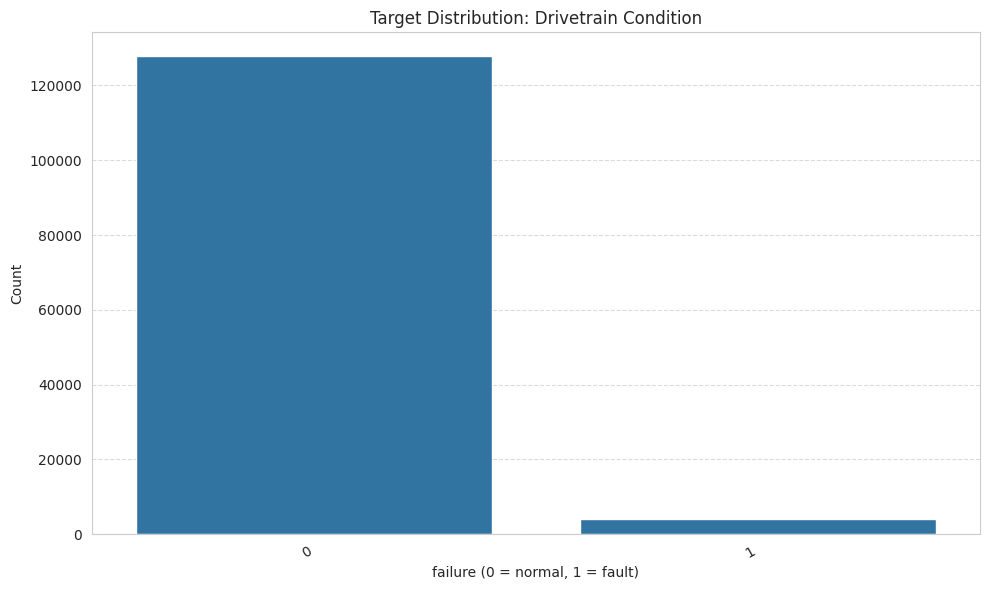

In [ ]:
#Failure
barchart(data, 'failure', title='Target Distribution: Drivetrain Condition', xlabel='failure (0 = normal, 1 = fault)')

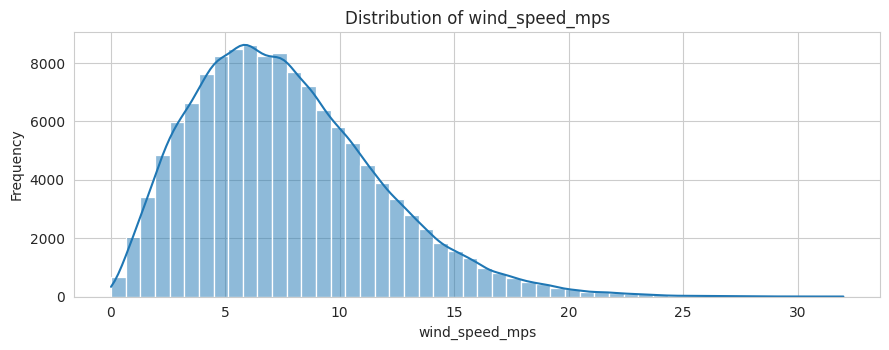

In [ ]:
#Wind_Speed_MPS
histogram(data, 'wind_speed_mps', title='Distribution of wind_speed_mps', xlabel='wind_speed_mps')


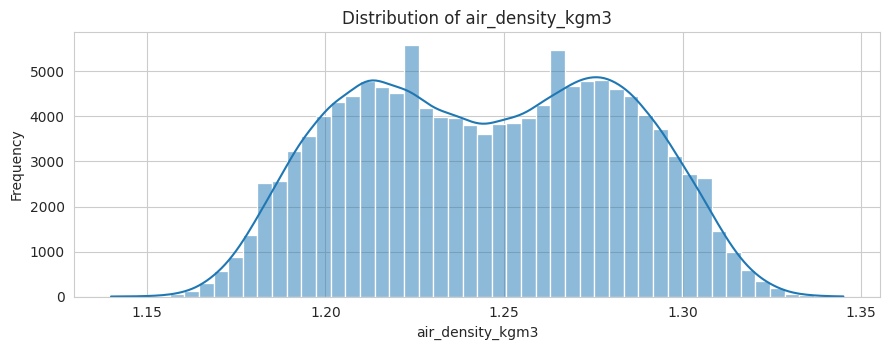

In [ ]:
# air_density_kgm3
histogram(data, 'air_density_kgm3', title='Distribution of air_density_kgm3', xlabel='air_density_kgm3')

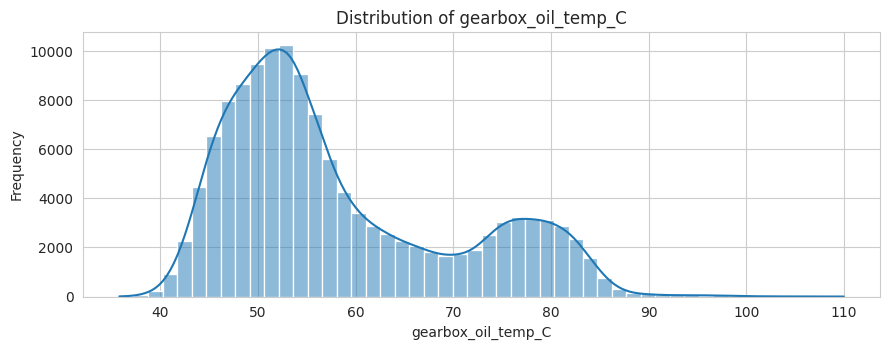

In [ ]:
# gearbox_oil_temp_C
histogram(data, 'gearbox_oil_temp_C', title='Distribution of gearbox_oil_temp_C', xlabel='gearbox_oil_temp_C')

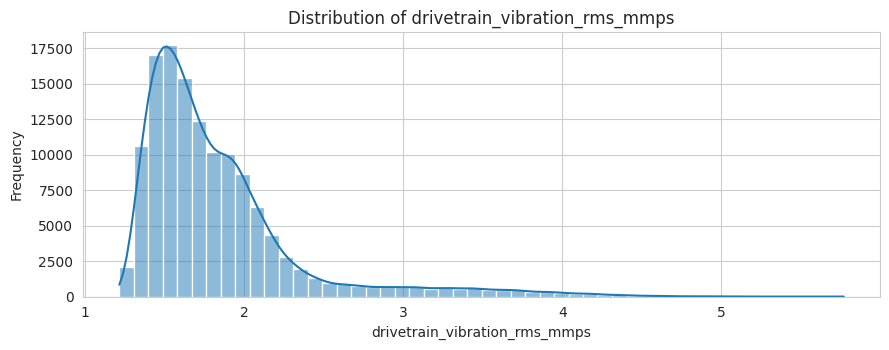

In [ ]:
histogram(data, 'drivetrain_vibration_rms_mmps', title='Distribution of drivetrain_vibration_rms_mmps', xlabel='drivetrain_vibration_rms_mmps')

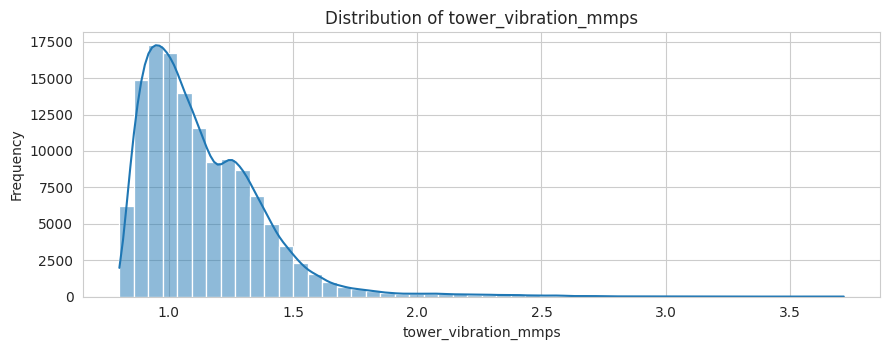

In [ ]:
histogram(data, 'tower_vibration_mmps', title='Distribution of tower_vibration_mmps', xlabel='tower_vibration_mmps')

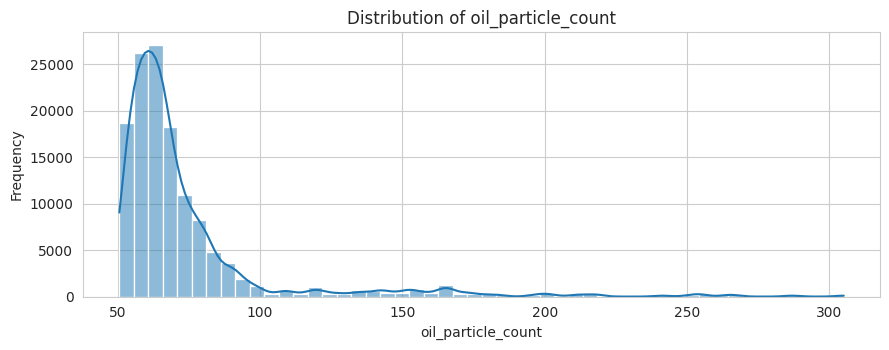

In [ ]:
histogram(data, 'oil_particle_count', title='Distribution of oil_particle_count', xlabel='oil_particle_count')

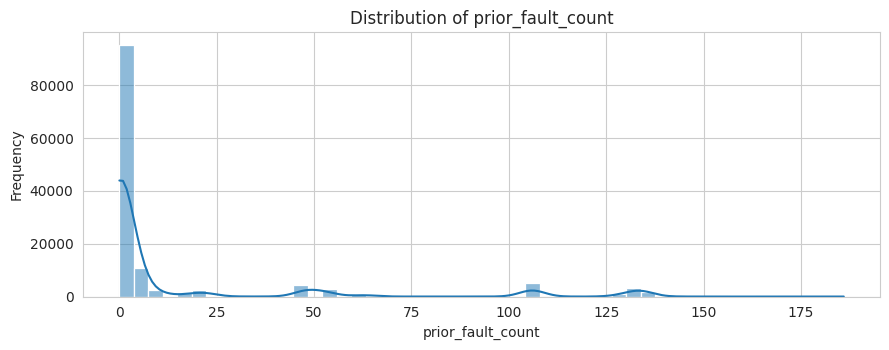

In [ ]:
histogram(data, 'prior_fault_count', title='Distribution of prior_fault_count', xlabel='prior_fault_count')

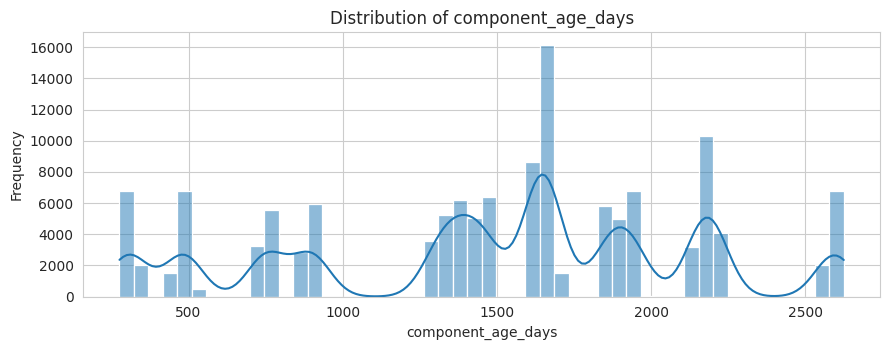

In [ ]:
histogram(data, 'component_age_days', title='Distribution of component_age_days', xlabel='component_age_days')

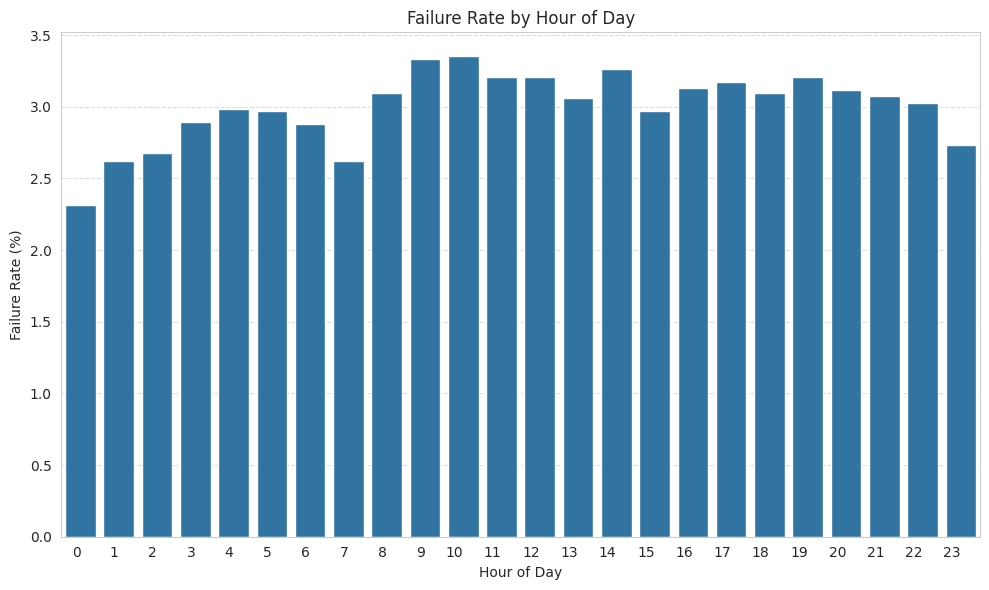

In [ ]:
# Calculate failure rate by hour
failure_rate_by_hour_df = data.groupby('hour')['failure'].mean().reset_index()
failure_rate_by_hour_df['failure_rate_pct'] = failure_rate_by_hour_df['failure'] * 100

# Plot using the barchart utility function
barchart(data_df=failure_rate_by_hour_df, x_col='hour', y_col='failure_rate_pct',
         title='Failure Rate by Hour of Day',
         xlabel='Hour of Day', ylabel='Failure Rate (%)', rot_degrees=0)

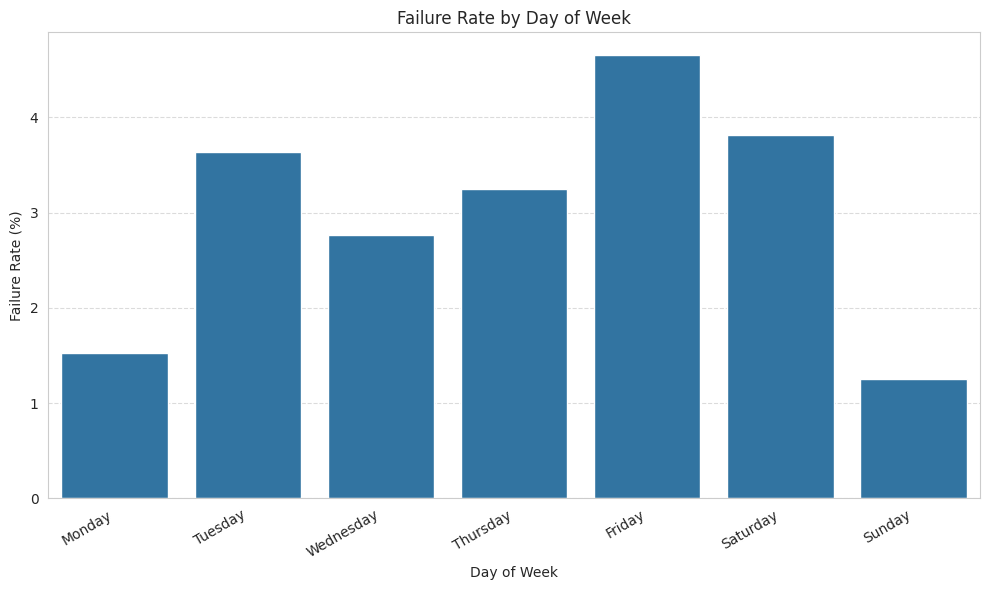

In [ ]:
failure_rate_by_day_df = data.groupby('dayofweek')['failure'].mean().reset_index()
failure_rate_by_day_df['failure_rate_pct'] = failure_rate_by_day_df['failure'] * 100
# Define the chronological order of days for sorting
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Map numerical dayofweek to names
day_name_map = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
failure_rate_by_day_df['dayofweek'] = failure_rate_by_day_df['dayofweek'].map(day_name_map)

# Convert 'dayofweek' to a categorical type with the defined order
failure_rate_by_day_df['dayofweek'] = pd.Categorical(failure_rate_by_day_df['dayofweek'], categories=day_order, ordered=True)

# Sort the DataFrame by the ordered 'dayofweek'
failure_rate_by_day_df = failure_rate_by_day_df.sort_values('dayofweek')

barchart(data_df=failure_rate_by_day_df, x_col='dayofweek', y_col='failure_rate_pct',
         title='Failure Rate by Day of Week',
         xlabel='Day of Week', ylabel='Failure Rate (%)', rot_degrees=30)

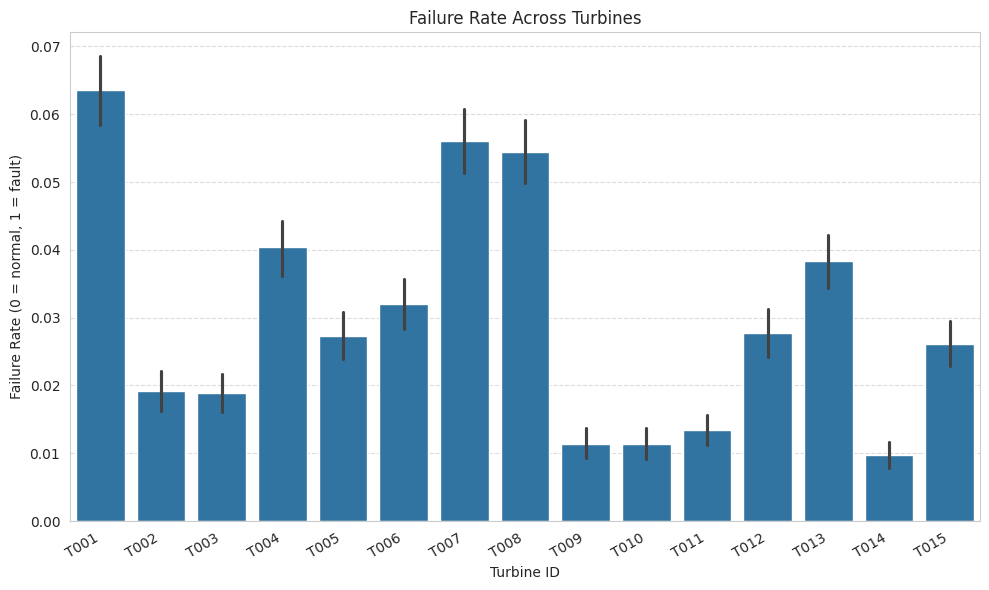

In [ ]:
barchart(data_df=data, x_col='turbine_id', y_col='failure', title='Failure Rate Across Turbines', xlabel='Turbine ID', ylabel='Failure Rate (0 = normal, 1 = fault)')

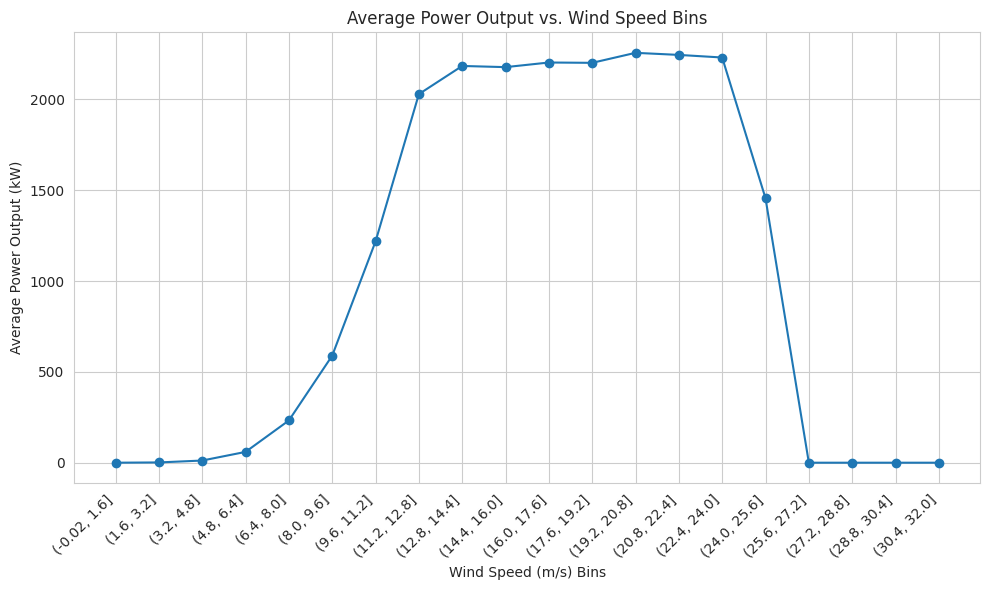

In [ ]:
wind_speed_bins = pd.cut(data['wind_speed_mps'], bins=20, precision=1)
power_output_mean = data.groupby(wind_speed_bins)['power_output_kW'].mean()

plt.figure(figsize=(10, 6))
plt.plot(power_output_mean.index.astype(str), power_output_mean.values, marker='o')
plt.xlabel('Wind Speed (m/s) Bins')
plt.ylabel('Average Power Output (kW)')
plt.title('Average Power Output vs. Wind Speed Bins')
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

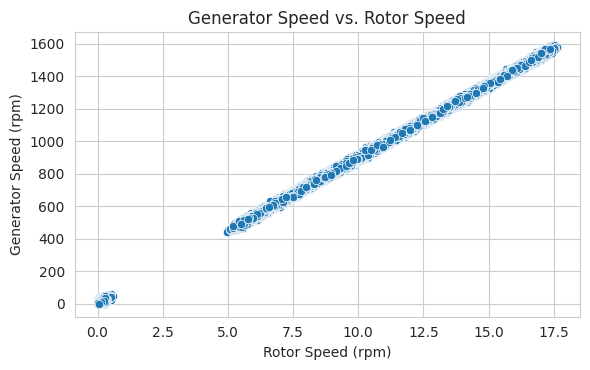

In [ ]:
scatterplot(data_df=data, x_col='rotor_speed_rpm', y_col='generator_speed_rpm',
            title='Generator Speed vs. Rotor Speed',
            xlabel='Rotor Speed (rpm)',
            ylabel='Generator Speed (rpm)')

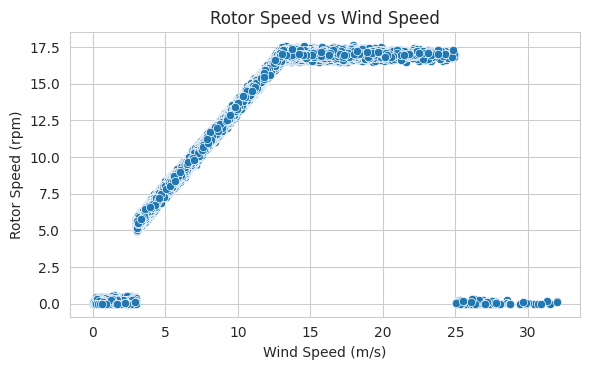

In [ ]:
scatterplot(data_df=data, x_col='wind_speed_mps', y_col='rotor_speed_rpm',
            title='Rotor Speed vs Wind Speed',
            xlabel='Wind Speed (m/s)',
            ylabel='Rotor Speed (rpm)')

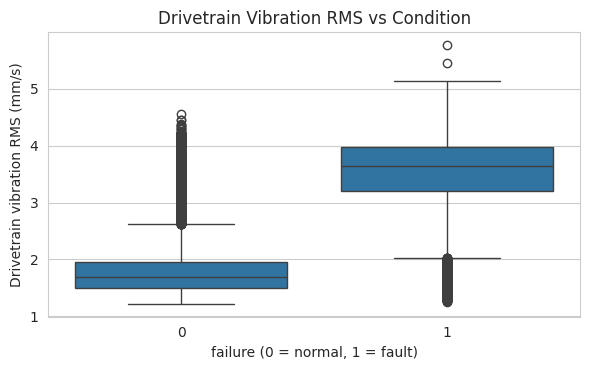

In [ ]:
boxplot(data, x_col='failure', y_col='drivetrain_vibration_rms_mmps', title='Drivetrain Vibration RMS vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Drivetrain vibration RMS (mm/s)')

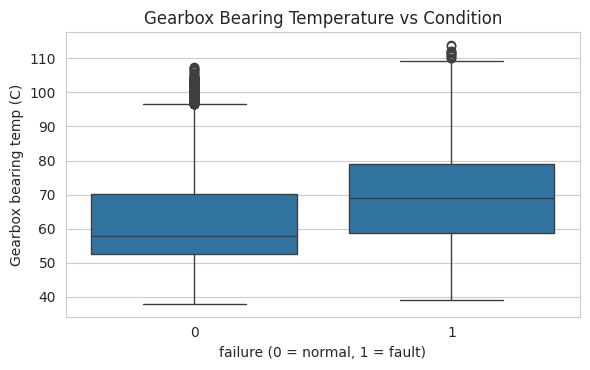

In [ ]:
boxplot(data, x_col='failure', y_col='gearbox_bearing_temp_C', title='Gearbox Bearing Temperature vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Gearbox bearing temp (C)')

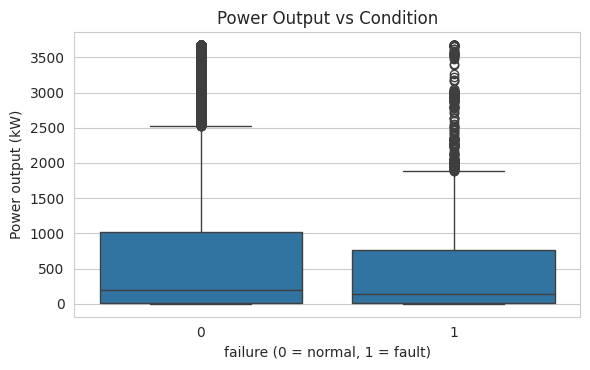

In [ ]:
boxplot(data, x_col='failure', y_col='power_output_kW', title='Power Output vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Power output (kW)')

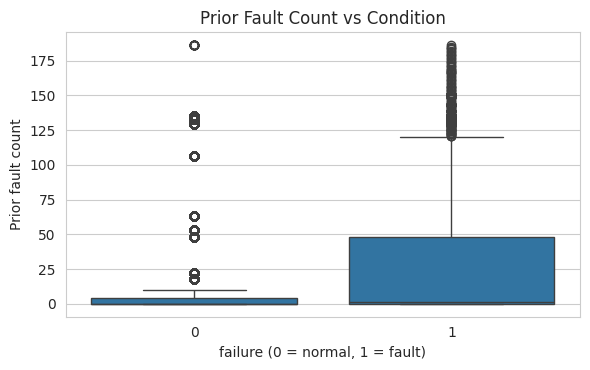

In [ ]:
boxplot(data, x_col='failure', y_col='prior_fault_count', title='Prior Fault Count vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Prior fault count')

In [ ]:
numerical_cols = ['rated_power_kW', 'wind_speed_mps', 'wind_direction_deg', 'turbulence_intensity', 'air_density_kgm3',
                  'ambient_temp_C', 'humidity_pct', 'power_output_kW', 'rotor_speed_rpm', 'generator_speed_rpm', 'blade_pitch_angle_deg',
                  'yaw_misalignment_deg', 'gearbox_oil_temp_C', 'gearbox_bearing_temp_C', 'generator_bearing_temp_C', 'generator_winding_temp_C',
                  'main_bearing_temp_C', 'nacelle_temp_C', 'drivetrain_vibration_rms_mmps', 'tower_vibration_mmps', 'vib_fft_bearing_bpfo',
                  'vib_fft_bearing_bpfi', 'vib_fft_gearmesh', 'vib_fft_sideband', 'oil_particle_count', 'oil_pressure_bar', 'operating_hours_total',
                  'cumulative_energy_MWh', 'load_cycles', 'hours_since_last_maintenance', 'prior_fault_count', 'component_age_days']

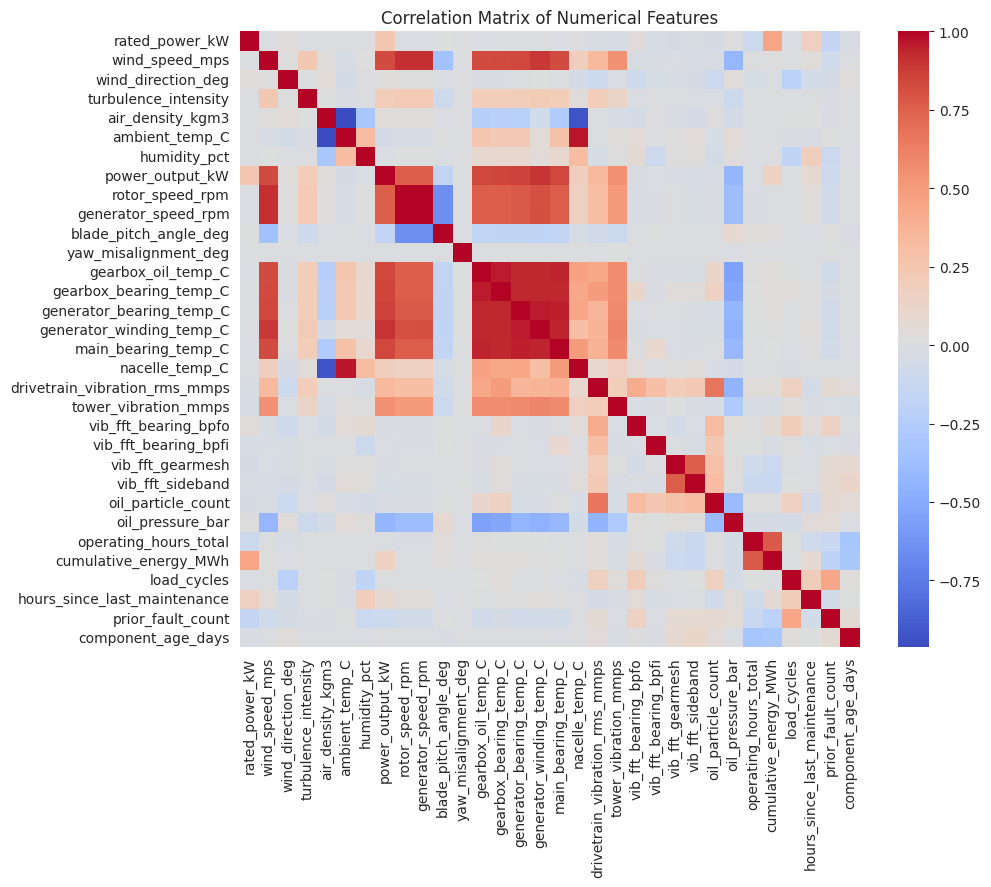

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(data[numerical_cols].corr(), annot=False, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [ ]:
data = data.sort_values(by=['timestamp','turbine_id'])

In [ ]:
n = len(data)

In [ ]:
# Uncomment the below train and validation indices to create a 70% train, 15% validation, and 15% test split.
# i_train = int(n * 0.70)
# i_val = int(n * 0.85)

# Uncomment the below train and validation indices to create a 80% train, 10% validation, and 10% test split.
# i_train = int(n * 0.80)
# i_val = int(n * 0.90)

# Uncomment the below train and validation indices to create a 90% train, 5% validation, and 5% test split.
# i_train = int(n * 0.90)
# i_val = int(n * 0.95)

In [ ]:
# Calculate indices for a 70% train, 15% validation, and 15% test split
i_train = int(n * 0.70)
i_val = int(n * 0.85)

data_train = data.iloc[:i_train]
data_val = data.iloc[i_train:i_val]
data_test = data.iloc[i_val:]

X_train = data_train.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_train = data_train['failure']

X_valid = data_val.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_valid = data_val['failure']

X_test = data_test.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_test = data_test['failure']

In [ ]:
print(f'Train split failure rate: {y_train.mean()*100:.2f}%')
print(f'Validation split failure rate: {y_valid.mean()*100:.2f}%')
print(f'Test split failure rate: {y_test.mean()*100:.2f}%')

Train split failure rate: 1.60%
Validation split failure rate: 5.26%
Test split failure rate: 7.29%


In [ ]:
# Calculate indices for a 80% train, 10% validation, and 10% test split
i_train = int(n * 0.80)
i_val = int(n * 0.90)

data_train = data.iloc[:i_train]
data_val = data.iloc[i_train:i_val]
data_test = data.iloc[i_val:]

X_train = data_train.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_train = data_train['failure']

X_valid = data_val.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_valid = data_val['failure']

X_test = data_test.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_test = data_test['failure']

In [ ]:
print(f'Train split failure rate: {y_train.mean()*100:.2f}%')
print(f'Validation split failure rate: {y_valid.mean()*100:.2f}%')
print(f'Test split failure rate: {y_test.mean()*100:.2f}%')

Train split failure rate: 2.27%
Validation split failure rate: 5.13%
Test split failure rate: 6.71%


In [ ]:
# Calculate indices for a 90% train, 5% validation, and 5% test split
i_train = int(n * 0.90)
i_val = int(n * 0.95)

data_train = data.iloc[:i_train]
data_val = data.iloc[i_train:i_val]
data_test = data.iloc[i_val:]

X_train = data_train.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_train = data_train['failure']

X_valid = data_val.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_valid = data_val['failure']

X_test = data_test.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_test = data_test['failure']

In [ ]:
print(f'Train split failure rate: {y_train.mean()*100:.2f}%')
print(f'Validation split failure rate: {y_valid.mean()*100:.2f}%')
print(f'Test split failure rate: {y_test.mean()*100:.2f}%')

Train split failure rate: 2.59%
Validation split failure rate: 5.07%
Test split failure rate: 8.35%


### Data Imputation & Scaling
We will impute the missing SCADA features using the median values from the training set, followed by standard scaling to normalize feature magnitudes.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Initialize Imputer and Scaler
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

# Fit on Train data and transform all splits
X_train_imputed = imputer.fit_transform(X_train)
X_valid_imputed = imputer.transform(X_valid)
X_test_imputed = imputer.transform(X_test)

# Scale the imputed data
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_valid_scaled = scaler.transform(X_valid_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Re-create DataFrames to retain column metadata
X_train_clean = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_valid_clean = pd.DataFrame(X_valid_scaled, columns=X_valid.columns, index=X_valid.index)
X_test_clean = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

# Verify there are no remaining missing values
print("Remaining missing values in train:", X_train_clean.isnull().sum().sum())
print("Remaining missing values in validation:", X_valid_clean.isnull().sum().sum())
print("Remaining missing values in test:", X_test_clean.isnull().sum().sum())


Remaining missing values in train: 0
Remaining missing values in validation: 0
Remaining missing values in test: 0


In [ ]:
print(((X_train.isnull().sum() / len(X_train) * 100).round(2)).loc[lambda x: x > 0])
print(((X_valid.isnull().sum() / len(X_valid) * 100).round(2)).loc[lambda x: x > 0])
print(((X_test.isnull().sum() / len(X_test) * 100).round(2)).loc[lambda x: x > 0])

gearbox_oil_temp_C          0.49
generator_bearing_temp_C    0.52
oil_pressure_bar            0.48
dtype: float64
gearbox_oil_temp_C          0.47
generator_bearing_temp_C    0.64
oil_pressure_bar            0.50
dtype: float64
gearbox_oil_temp_C          0.55
generator_bearing_temp_C    0.44
oil_pressure_bar            0.59
dtype: float64


In [ ]:
X_train['gearbox_oil_temp_C'] = X_train['gearbox_oil_temp_C'].median()
X_valid['gearbox_oil_temp_C'] = X_valid['gearbox_oil_temp_C'].median()
X_test['gearbox_oil_temp_C']  = X_test['gearbox_oil_temp_C'].median()

In [ ]:
X_train['generator_bearing_temp_C'] = X_train['generator_bearing_temp_C'].median()
X_valid['generator_bearing_temp_C'] = X_valid['generator_bearing_temp_C'].median()
X_test['generator_bearing_temp_C']  = X_test['generator_bearing_temp_C'].median()

In [ ]:
X_train['oil_pressure_bar'] = X_train['oil_pressure_bar'].median()
X_valid['oil_pressure_bar'] = X_valid['oil_pressure_bar'].median()
X_test['oil_pressure_bar']  = X_test['oil_pressure_bar'].median()

In [ ]:
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier (sklearn or tensorflow)
    predictors: independent variables
    target: dependent variable
    """

    # 1. Get raw predictions
    pred_raw = model.predict(predictors)

    # 2. Check the shape or values to handle DL vs ML models safely
    # If the predictions are probabilities (floats between 0 and 1, not exactly 0 or 1)
    # We check if any value falls strictly between 0 and 1
    if np.issubdtype(pred_raw.dtype, np.floating) and not np.all(np.isin(pred_raw, [0.0, 1.0])):
        # FOR TENSORFLOW DL MODELS: threshold the probabilities at 0.5
        pred = (pred_raw > 0.5).astype(int)
    else:
        # FOR SKLEARN ML MODELS: use them directly
        pred = pred_raw

    # Flatten predictions to ensure they match target shape perfectly
    pred = np.array(pred).flatten()

    # 3. Compute metrics
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    # 4. Creating a dataframe of metrics
    data_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1},
        index=[0],
    )

    return data_perf

In [ ]:
def plot_confusion_matrix(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    # 1. Get raw predictions
    y_pred_raw = model.predict(predictors)

    # 2. Check if predictions are probabilities (typical for Keras/TF models or some ML models with predict_proba)
    # If y_pred_raw contains float values between 0 and 1, it's likely probabilities.
    if np.issubdtype(y_pred_raw.dtype, np.floating) and np.any((y_pred_raw > 0) & (y_pred_raw < 1)):
        # Binarize probabilities using a threshold (e.g., 0.5)
        y_pred = (y_pred_raw > 0.5).astype(int)
    else:
        # Use predictions directly (typical for scikit-learn classifiers that return binary labels)
        y_pred = y_pred_raw

    # Ensure y_pred is flattened to a 1D array, as confusion_matrix expects this format.
    y_pred = np.array(y_pred).flatten()

    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.show() # Added plt.show() to explicitly display the plot

In [ ]:
# Set the random state for reproducibility.
# Choose an integer between 0 and 100.
# Using the same random state ensures the model produces the same results each time it is trained.
RS = 42

In [ ]:
dt_class_model = DecisionTreeClassifier(class_weight='balanced', random_state=RS)

In [ ]:
dt_class_model.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

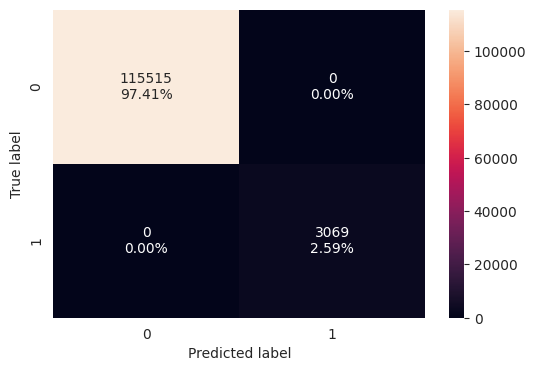

In [ ]:
plot_confusion_matrix(dt_class_model, X_train, y_train)

In [ ]:
decision_tree_class_weight_perf_train = model_performance_classification(
    dt_class_model, X_train, y_train
)
decision_tree_class_weight_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


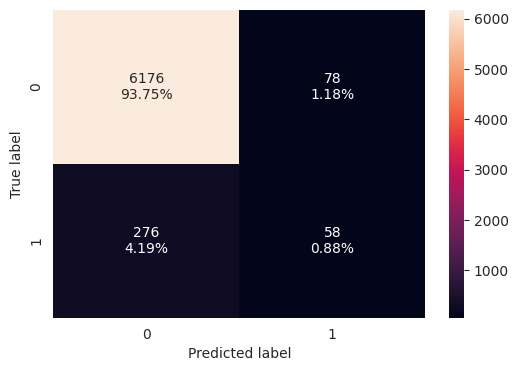

In [ ]:
plot_confusion_matrix(dt_class_model, X_valid, y_valid)

In [ ]:
decision_tree_class_weight_perf_valid = model_performance_classification(
    dt_class_model, X_valid, y_valid
)
decision_tree_class_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.946266,0.173653,0.426471,0.246809


In [ ]:
rf_class_model = RandomForestClassifier(class_weight='balanced', random_state=RS)

In [ ]:
rf_class_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

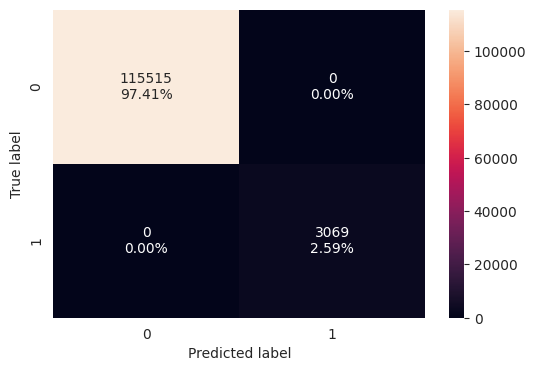

In [ ]:
plot_confusion_matrix(rf_class_model, X_train, y_train)

In [ ]:
decision_tree_class_weight_perf_valid = model_performance_classification(
    dt_class_model, X_valid, y_valid
)
decision_tree_class_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.946266,0.173653,0.426471,0.246809


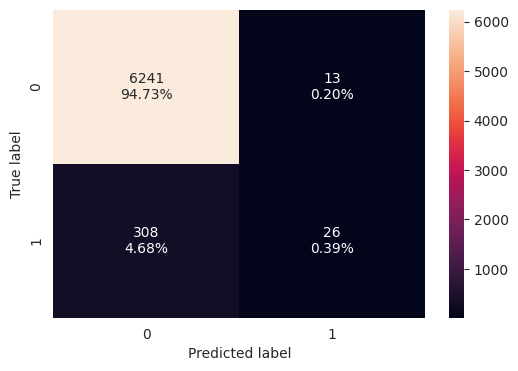

In [ ]:
plot_confusion_matrix(rf_class_model, X_valid, y_valid)

In [ ]:
random_forest_class_weight_perf_valid = model_performance_classification(
    rf_class_model, X_valid, y_valid
)
random_forest_class_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.951275,0.077844,0.666667,0.13941


In [ ]:
gb_model = GradientBoostingClassifier(random_state=RS)

In [ ]:
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

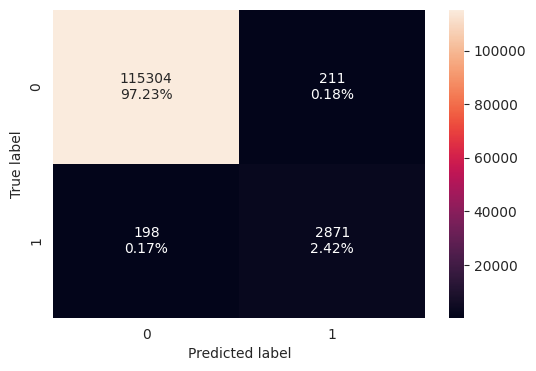

In [ ]:
plot_confusion_matrix(gb_model, X_train, y_train)

In [ ]:
gradient_boosting_weight_perf_train = model_performance_classification(
    gb_model, X_train, y_train
)
gradient_boosting_weight_perf_train

,Accuracy,Recall,Precision,F1
0,0.996551,0.935484,0.931538,0.933507


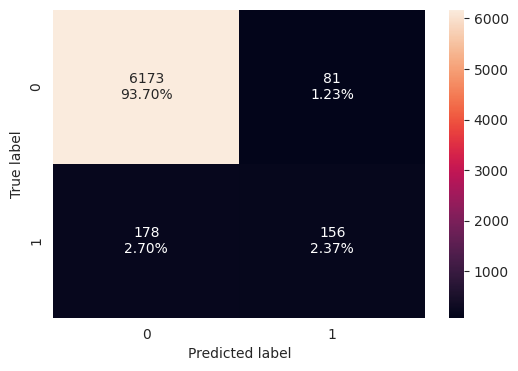

In [ ]:
plot_confusion_matrix(gb_model, X_valid, y_valid)

In [ ]:
gradient_boosting_weight_perf_valid = model_performance_classification(
    gb_model, X_valid, y_valid
)
gradient_boosting_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.960686,0.467066,0.658228,0.54641


In [ ]:
neg_count = y_train.value_counts()[0]
pos_count = y_train.value_counts()[1]
scale_pos_weight_value = neg_count / pos_count

print(f"Negative Samples: {neg_count}")
print(f"Positive Samples: {pos_count}")
print(f"Scale Pos Weight (neg/pos): {scale_pos_weight_value:.2f}")

Negative Samples: 115515
Positive Samples: 3069
Scale Pos Weight (neg/pos): 37.64


In [ ]:
xgb_class_model = XGBClassifier(scale_pos_weight=scale_pos_weight_value, random_state=RS)

In [ ]:
xgb_class_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
xgb_class_weight_perf_train = model_performance_classification(
    xgb_class_model, X_train, y_train
)
xgb_class_weight_perf_train

,Accuracy,Recall,Precision,F1
0,0.999772,1.0,0.991279,0.99562


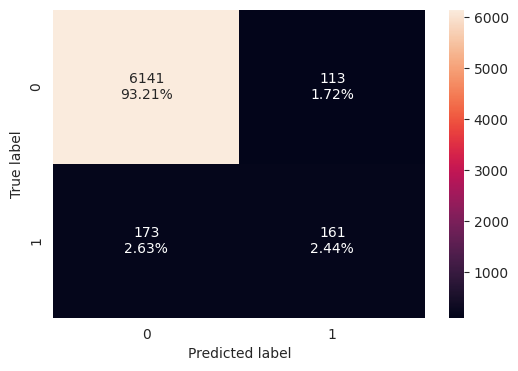

In [ ]:
plot_confusion_matrix(xgb_class_model, X_valid, y_valid)

In [ ]:
xgb_class_weight_perf_valid = model_performance_classification(
    xgb_class_model, X_valid, y_valid
)
xgb_class_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.956588,0.482036,0.587591,0.529605


In [ ]:
tf.keras.backend.clear_session()

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Choose the number of neurons for the first hidden layer between 8 and 128 integer value only
# Fewer neurons (8–32) create a simpler model that trains faster and is less likely to overfit.
# More neurons (64–128) allow the model to learn more complex patterns but increase training time and the risk of overfitting.

# Choose the activation function for the first hidden layer.
# Common choices: 'relu', 'tanh', or 'sigmoid'.

model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model.add(Dense(7, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,703 (10.56 KB)

 Trainable params: 2,703 (10.56 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = 'sgd'
loss = 'binary_crossentropy'
model.compile(loss=loss, optimizer=optimizer, metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

In [ ]:
# Choose the number of training epochs between 10 and 100.
# Fewer epochs (10–30) train faster but may underfit the data.
# More epochs (50–100) allow the model to learn more patterns but may increase the risk of overfitting.

epochs =30

# Choose the batch size between 16 and 128.
# Smaller batch sizes (16–32) can improve generalization but increase training time.
# Larger batch sizes (64–128) train faster but may require more memory and sometimes reduce model generalization.

batch_size = 64

In [ ]:
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: weights[i] for i in range(len(weights))}

In [ ]:
start = time.time()
history = model.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) , class_weight=class_weight_dict ,batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/30
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - binary_accuracy: 0.9119 - loss: 0.1483 - precision: 0.2260 - recall: 0.9909 - val_binary_accuracy: 0.8802 - val_loss: 0.2762 - val_precision: 0.2767 - val_recall: 0.8443
Epoch 2/30
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - binary_accuracy: 0.9705 - loss: 0.0537 - precision: 0.4674 - recall: 0.9997 - val_binary_accuracy: 0.9194 - val_loss: 0.1819 - val_precision: 0.3667 - val_recall: 0.8114
Epoch 3/30
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9750 - loss: 0.0451 - precision: 0.5087 - recall: 0.9990 - val_binary_accuracy: 0.9281 - val_loss: 0.1646 - val_precision: 0.3946 - val_recall: 0.7844
Epoch 4/30
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - binary_accuracy: 0.9778 - loss: 0.0406 - precision: 0.5382 - recall: 0.9993 - val_binary_accuracy: 0.9282 - val_loss: 0.1641 - val_precision: 0.3955 - val_recall: 0.7874
Epoch 5/30
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - binary_accuracy: 0.9797 - loss: 0.0373 -

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  91.77455973625183


3706/3706 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step


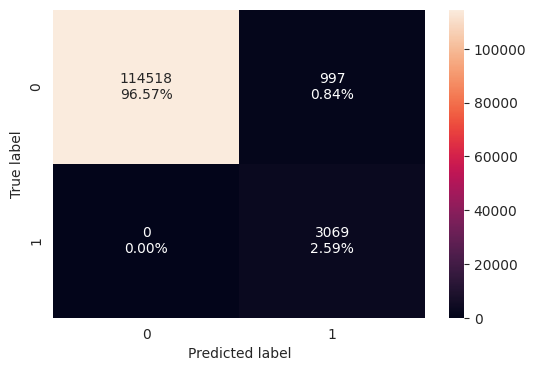

In [ ]:
plot_confusion_matrix(model, X_train_scaled, y_train)

In [ ]:
ann_perf_train = model_performance_classification(
    model, X_train_scaled, y_train
)
print("ANN Baseline Training Performance:")
ann_perf_train

3706/3706 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
ANN Baseline Training Performance:


,Accuracy,Recall,Precision,F1
0,0.991592,1.0,0.754796,0.860266


206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


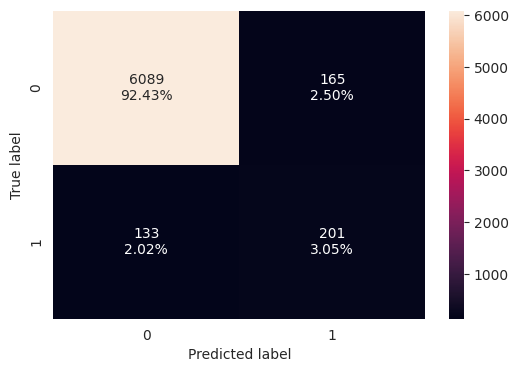

In [ ]:
plot_confusion_matrix(model, X_valid_scaled, y_valid)

In [ ]:
ann_perf_valid = model_performance_classification(
    model, X_valid_scaled, y_valid
)
print("\nANN Baseline Validation Performance:")
ann_perf_valid

206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

ANN Baseline Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.954766,0.601796,0.54918,0.574286


In [ ]:
print("Training performance comparison:")

all_models_train_comp_data = pd.concat([
    decision_tree_class_weight_perf_train.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_train.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_train.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_train.T.rename(columns={0: 'XGBoost'}),
    ann_perf_train.T.rename(columns={0: 'Neural Network'})
], axis=1)
all_models_train_comp_data

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,1.0,1.0,0.996551,0.999772,0.991592
Recall,1.0,1.0,0.935484,1.000000,1.000000
Precision,1.0,1.0,0.931538,0.991279,0.754796
F1,1.0,1.0,0.933507,0.995620,0.860266


In [ ]:
print("Validation performance comparison:")

all_models_valid_comp_data = pd.concat([
    decision_tree_class_weight_perf_valid.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_valid.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_valid.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_valid.T.rename(columns={0: 'XGBoost'}),
    ann_perf_valid.T.rename(columns={0: 'Neural Network'})
], axis=1)
all_models_valid_comp_data

Validation performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,0.946266,0.951275,0.960686,0.956588,0.954766
Recall,0.173653,0.077844,0.467066,0.482036,0.601796
Precision,0.426471,0.666667,0.658228,0.587591,0.549180
F1,0.246809,0.139410,0.546410,0.529605,0.574286


In [ ]:
param_grid = {
    'n_estimators': [50, 100, 150, 200],          # Number of trees. Smaller values (50–100) train faster but may underfit. Larger values (100–300) improve learning but increase training time.
    'learning_rate': [0.01, 0.05, 0.1, 0.2],       # Step size for learning. Smaller values (0.01–0.05) learn gradually and need more trees. Larger values (0.1–0.3) learn faster but may overshoot.
    'max_depth': [3, 5, 7],              # Maximum tree depth. Smaller values (3–5) reduce overfitting. Larger values (6–10) capture more complex patterns but may overfit.
    'min_child_weight': [1, 3, 5],       # Minimum weight required for a split. Smaller values (1–3) create more complex trees. Larger values (5–10) make the model more conservative.
    'gamma': [0, 0.1, 0.2, 0.3],             # Minimum loss reduction for a split. Smaller values (0–0.1) allow more splits. Larger values (0.3–1) reduce unnecessary splits.
    'subsample': [0.7, 0.8, 0.9, 1.0],            # Fraction of training samples per tree. Smaller values (0.6–0.8) improve generalization. Larger values (0.9–1.0) use more data but may overfit.
    'colsample_bytree': [0.4, 0.6, 0.8, 1.0],     # Fraction of features per tree. Smaller values (0.4–0.7) increase tree diversity. Larger values (0.8–1.0) use more features and may improve fit.
    'reg_alpha': [0, 0.001, 0.01, 0.1],       # L1 regularization. Smaller values (0–0.001) apply little regularization. Larger values (0.01–0.1) reduce overfitting by encouraging sparsity.
    'reg_lambda': [0.1, 1.0, 5.0, 10.0]            # L2 regularization. Smaller values (0.1–1) apply light regularization. Larger values (5–10) provide stronger regularization.
}

In [ ]:
xgb_randomized_cv = RandomizedSearchCV(
    estimator=xgb_class_model,
    param_distributions=param_grid,
    n_iter=10,
    n_jobs=-1,
    scoring='f1',
    cv=3,
    random_state=RS
)

xgb_randomized_cv.fit(X_train, y_train)

print("Best parameters are {} with CV score={:.4f}:".format(xgb_randomized_cv.best_params_, xgb_randomized_cv.best_score_))

Best parameters are {'subsample': 0.7, 'reg_lambda': 10.0, 'reg_alpha': 0.001, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0.2, 'colsample_bytree': 1.0} with CV score=0.2576:


In [ ]:
tuned_xgb = xgb_randomized_cv.best_estimator_
tuned_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0.2, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
xgb_tuned_perf_train = model_performance_classification(
    tuned_xgb, X_train, y_train
)
xgb_tuned_perf_train

,Accuracy,Recall,Precision,F1
0,0.983927,0.998697,0.617073,0.762817


In [ ]:
xgb_tuned_perf_valid = model_performance_classification(
    tuned_xgb, X_valid, y_valid
)
xgb_tuned_perf_valid

,Accuracy,Recall,Precision,F1
0,0.939587,0.814371,0.447368,0.577495


In [ ]:
tf.keras.backend.clear_session()

In [ ]:
model1 = Sequential()

# Choose the number of neurons for the first hidden layer between 32 and 256.
# Fewer neurons (32–64) create a simpler model that trains faster and is less likely to overfit.
# More neurons (128–256) can learn more complex patterns but increase training time and the risk of overfitting.
#
# Choose the activation function for the first hidden layer.
# Common choices are 'relu', 'tanh', or 'sigmoid'.
model1.add(Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)))

model1.add(BatchNormalization())

# Choose the dropout rate between 0.2 and 0.5.
# Lower values (0.2–0.3) retain more information but provide less regularization.
# Higher values (0.4–0.5) reduce overfitting more aggressively but may lead to underfitting if too high.
model1.add(Dropout(0.3))

# Choose the number of neurons for the second hidden layer between 16 and 128.
# Fewer neurons (16–32) keep the model simple and reduce overfitting.
# More neurons (64–128) increase model capacity but may overfit on smaller datasets.
#
# Choose the activation function for the second hidden layer.
# Common choices are 'relu', 'tanh', or 'sigmoid'.
model1.add(Dense(64, activation='relu'))

model1.add(BatchNormalization())

# Choose the dropout rate between 0.2 and 0.5.
# Lower values (0.2–0.3) retain more information but provide less regularization.
# Higher values (0.4–0.5) reduce overfitting more aggressively but may lead to underfitting if too high.
model1.add(Dropout(0.3))

model1.add(Dense(1, activation='sigmoid'))

In [ ]:
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,185 (51.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# Uncomment one of the following optimizers.

# optimizer = 'adam'
# optimizer = 'sgd'

loss = 'binary_crossentropy'
model1.compile(loss=loss, optimizer=optimizer, metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

In [ ]:
# Choose the number of training epochs between 20 and 150.
# Fewer epochs (20–50) train faster but may underfit the data.
# More epochs (75–150) allow the model to learn more complex patterns but may increase the risk of overfitting.

epochs = 50

# Choose the batch size between 16 and 128.
# Smaller batch sizes (16–32) update model weights more frequently and may improve generalization but increase training time.
# Larger batch sizes (64–128) train faster and use hardware more efficiently but may require more memory and sometimes reduce generalization.

batch_size = 64

In [ ]:
start_time = time.time()
history1 = model1.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_valid_scaled, y_valid),
    class_weight=class_weight_dict,
    batch_size=batch_size,
    epochs=epochs
)
end_time = time.time()
print(f"Training complete! Time taken: {end_time - start_time:.2f} seconds")

Epoch 1/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - binary_accuracy: 0.9860 - loss: 0.0320 - precision: 0.6490 - recall: 0.9977 - val_binary_accuracy: 0.9265 - val_loss: 0.2132 - val_precision: 0.3794 - val_recall: 0.7066
Epoch 2/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9859 - loss: 0.0326 - precision: 0.6481 - recall: 0.9961 - val_binary_accuracy: 0.9252 - val_loss: 0.2267 - val_precision: 0.3732 - val_recall: 0.7006
Epoch 3/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9860 - loss: 0.0336 - precision: 0.6487 - recall: 0.9974 - val_binary_accuracy: 0.9148 - val_loss: 0.2619 - val_precision: 0.3343 - val_recall: 0.6856
Epoch 4/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - binary_accuracy: 0.9865 - loss: 0.0322 - precision: 0.6581 - recall: 0.9964 - val_binary_accuracy: 0.9250 - val_loss: 0.2314 - val_precision: 0.3746 - val_recall: 0.7156
Epoch 5/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9863 - loss: 0.0321 -

In [ ]:
start = time.time()
history = model1.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) ,class_weight=class_weight_dict, batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - binary_accuracy: 0.9016 - loss: 0.1995 - precision: 0.2059 - recall: 0.9814 - val_binary_accuracy: 0.8121 - val_loss: 0.5291 - val_precision: 0.2038 - val_recall: 0.9311
Epoch 2/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9582 - loss: 0.1027 - precision: 0.3814 - recall: 0.9896 - val_binary_accuracy: 0.8471 - val_loss: 0.4277 - val_precision: 0.2406 - val_recall: 0.9341
Epoch 3/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9654 - loss: 0.0845 - precision: 0.4270 - recall: 0.9889 - val_binary_accuracy: 0.8590 - val_loss: 0.4055 - val_precision: 0.2575 - val_recall: 0.9461
Epoch 4/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9698 - loss: 0.0725 - precision: 0.4613 - recall: 0.9912 - val_binary_accuracy: 0.8881 - val_loss: 0.3294 - val_precision: 0.3049 - val_recall: 0.9431
Epoch 5/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - binary_accuracy: 0.9702 - loss: 0.0721 -

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  257.30306220054626


3706/3706 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step


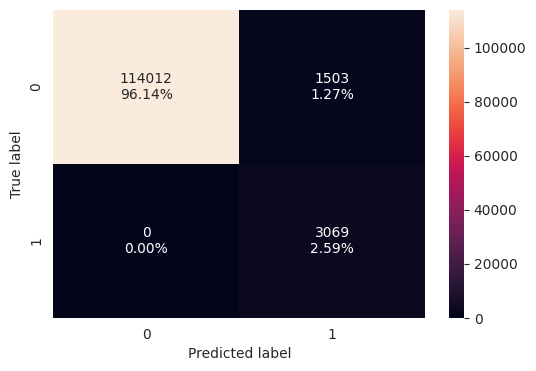

In [ ]:
plot_confusion_matrix(model1, X_train_scaled, y_train)

In [ ]:
ann_tuned_perf_train = model_performance_classification(
    model1, X_train_scaled, y_train
)
print("ANN Tuned Training Performance:")
ann_tuned_perf_train

3706/3706 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
ANN Tuned Training Performance:


,Accuracy,Recall,Precision,F1
0,0.987325,1.0,0.67126,0.803298


206/206 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


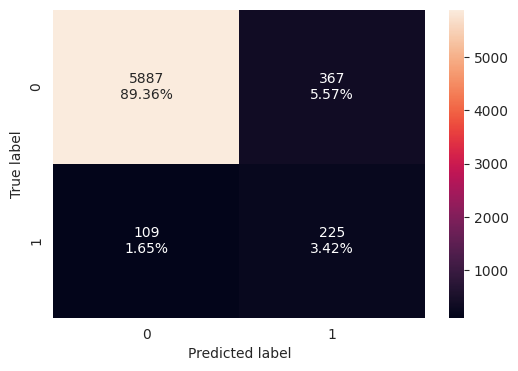

In [ ]:
plot_confusion_matrix(model1, X_valid_scaled, y_valid)

In [ ]:
ann_tuned_perf_valid = model_performance_classification(
    model1, X_valid_scaled, y_valid
)
print("\nANN Tuned Validation Performance:")
ann_tuned_perf_valid

206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

ANN Tuned Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.927747,0.673653,0.380068,0.485961


In [ ]:
# Parameter grid for Decision Tree hyperparameter tuning
dt_param_grid = {
    'criterion': ['gini', 'entropy'],          # Splitting criterion. 'gini' is faster, while 'entropy' uses information gain and may produce slightly different splits.
    'max_depth': [3, 5, 7],                    # Maximum tree depth. Smaller values (3–5) reduce overfitting. Larger values (7–15) capture more complex patterns but may overfit.
    'min_samples_split': [2, 5, 10],      # Minimum samples required to split a node. Smaller values (2–5) allow more splits. Larger values (10–20) make the tree more conservative.
    'min_samples_leaf': [1, 3, 5],       # Minimum samples required in a leaf node. Smaller values (1–3) create detailed trees. Larger values (5–10) produce smoother, more generalized trees.
    'max_features': ['sqrt', 'log2']           # Number of features considered at each split. 'sqrt' considers more features than 'log2', while 'log2' increases randomness and may reduce overfitting.
}

In [ ]:
# Define search configurations
n_iter = 10
metric_of_choice = 'recall'

dt_randomized_cv = RandomizedSearchCV(estimator=dt_class_model, param_distributions=dt_param_grid, n_iter=n_iter, n_jobs=-1, scoring=metric_of_choice, cv=5, random_state=1)

dt_randomized_cv.fit(X_train, y_train)  # fit the search on the training data

print("Best parameters are {} with CV score={}:".format(dt_randomized_cv.best_params_, dt_randomized_cv.best_score_))

Best parameters are {'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'log2', 'max_depth': 5, 'criterion': 'entropy'} with CV score=0.6820023274226716:


In [ ]:
dt_randomized_cv.best_estimator_

DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=5, max_features='log2', min_samples_leaf=5,
                       min_samples_split=10, random_state=42)

In [ ]:
dt_tuned_perf_train = model_performance_classification(
    tuned_dt, X_train, y_train
)
dt_tuned_perf_train

,Accuracy,Recall,Precision,F1
0,0.955323,0.997067,0.366511,0.535996


In [ ]:
dt_tuned_perf_valid = model_performance_classification(
    tuned_dt, X_valid, y_valid
)
dt_tuned_perf_valid

,Accuracy,Recall,Precision,F1
0,0.927292,0.661677,0.376491,0.479913


In [ ]:
# Parameter grid for Random Forest hyperparameter tuning
rf_param_grid = {
    'n_estimators': [20, 50, 100, 150],          # Number of trees. Smaller values (20–50) train faster but may underfit. Larger values (100–300) improve stability but increase training time.
    'max_depth': [2, 5, 10],                     # Maximum tree depth. Smaller values (2–5) reduce overfitting. Larger values (7–15) capture more complex patterns but may overfit.
    'min_samples_split': [2, 5, 10],             # Minimum samples required to split a node. Smaller values (2–5) allow more splits. Larger values (10–20) make the trees more conservative.
    'min_samples_leaf': [1, 3, 5],               # Minimum samples required in a leaf node. Smaller values (1–3) create more detailed trees. Larger values (5–10) improve generalization.
    'max_features': ['sqrt', 'log2']             # Number of features considered at each split. 'sqrt' considers more features than 'log2', while 'log2' increases tree diversity and may reduce overfitting.
}

In [ ]:
rf_randomized_cv = RandomizedSearchCV(estimator=rf_class_model, param_distributions=rf_param_grid, n_iter=n_iter, n_jobs=-1, scoring=metric_of_choice, cv=5, random_state=1)

rf_randomized_cv.fit(X_train, y_train)

print("Best parameters are {} with CV score={}:".format(rf_randomized_cv.best_params_, rf_randomized_cv.best_score_))

Best parameters are {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 2} with CV score=0.7858856162090643:


In [ ]:
rf_randomized_cv.best_estimator_

RandomForestClassifier(class_weight='balanced', max_depth=2, min_samples_leaf=5,
                       min_samples_split=10, random_state=42)

In [ ]:
from sklearn.base import clone

# Clone the best estimator to get an unfitted model with the optimized hyperparameters
tuned_rf = clone(rf_randomized_cv.best_estimator_)
tuned_rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=2, min_samples_leaf=5,
                       min_samples_split=10, random_state=42)

In [ ]:
rf_tuned_perf_train = model_performance_classification(
    tuned_rf, X_train, y_train
)
rf_tuned_perf_train

,Accuracy,Recall,Precision,F1
0,0.966589,0.835125,0.425818,0.56404


In [ ]:
rf_tuned_perf_valid = model_performance_classification(
    tuned_rf, X_valid, y_valid
)
rf_tuned_perf_valid

,Accuracy,Recall,Precision,F1
0,0.900121,0.637725,0.284,0.392989


In [ ]:
# Parameter grid for Gradient Boosting hyperparameter tuning
gb_param_grid = {
    'n_estimators': [20, 50, 100],      # Number of boosting stages. Smaller values (20–50) train faster but may underfit. Larger values (100–300) improve learning but increase training time.
    'learning_rate': [0.01, 0.05, 0.1],   # Step size for learning. Smaller values (0.01–0.05) learn gradually and often require more trees. Larger values (0.1–0.3) learn faster but may overfit.
    'max_depth': [3, 5, 7],          # Maximum depth of each tree. Smaller values (3–5) reduce overfitting. Larger values (7–10) capture more complex patterns but may overfit.
    'subsample': [0.5, 0.7, 0.9],        # Fraction of training samples used for each boosting stage. Smaller values (0.5–0.7) improve generalization. Larger values (0.8–1.0) use more data and may improve fit but increase overfitting risk.
    'max_features': ['sqrt', 'log2']       # Number of features considered at each split. 'sqrt' considers more features than 'log2', while 'log2' increases randomness and may reduce overfitting.
}

In [ ]:
gb_randomized_cv = RandomizedSearchCV(estimator=gb_model, param_distributions=gb_param_grid, n_iter=n_iter, n_jobs=-1, scoring=metric_of_choice, cv=3, random_state=1)

gb_randomized_cv.fit(X_train, y_train)

print("Best parameters are {} with CV score={}:".format(gb_randomized_cv.best_params_, gb_randomized_cv.best_score_))

Best parameters are {'subsample': 0.9, 'n_estimators': 100, 'max_features': 'sqrt', 'max_depth': 3, 'learning_rate': 0.1} with CV score=0.4102313457152167:


In [ ]:
gb_randomized_cv.best_estimator_

GradientBoostingClassifier(max_features='sqrt', random_state=42, subsample=0.9)

In [ ]:
from sklearn.base import clone

tuned_gb = clone(gb_randomized_cv.best_estimator_)
tuned_gb.fit(X_train, y_train)

GradientBoostingClassifier(max_features='sqrt', random_state=42, subsample=0.9)

In [ ]:
gb_tuned_perf_train = model_performance_classification(tuned_gb, X_train, y_train)
print("Tuned Gradient Boosting Training Performance:")
display(gb_tuned_perf_train)

gb_tuned_perf_valid = model_performance_classification(tuned_gb, X_valid, y_valid)
print("\nTuned Gradient Boosting Validation Performance:")
display(gb_tuned_perf_valid)

Tuned Gradient Boosting Training Performance:


,Accuracy,Recall,Precision,F1
0,0.995978,0.926686,0.918605,0.922628



Tuned Gradient Boosting Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.958713,0.362275,0.672222,0.470817


In [ ]:
gb_tuned_perf_train = model_performance_classification(
    tuned_gb, X_train, y_train
)
gb_tuned_perf_train

,Accuracy,Recall,Precision,F1
0,0.995978,0.926686,0.918605,0.922628


In [ ]:
gb_tuned_perf_valid = model_performance_classification(
    tuned_gb, X_valid, y_valid
)
gb_tuned_perf_valid

,Accuracy,Recall,Precision,F1
0,0.958713,0.362275,0.672222,0.470817


In [ ]:
print("Training performance comparison:")

# Uncomment the chosen tuned models to evaluate whether hyperparameter tuning improved
# the training performance compared to the original models.

all_models_train_comp_data = pd.concat([
    all_models_train_comp_data,
    # xgb_tuned_perf_train.T.rename(columns={0: 'XGBoost (Tuned)'}),
    # ann_tuned_perf_train.T.rename(columns={0: 'Neural Network (Tuned)'}),
    # dt_tuned_perf_train.T.rename(columns={0: 'Decision Tree (Tuned)'}),
    # rf_tuned_perf_train.T.rename(columns={0: 'Random Forest (Tuned)'}),
    # gb_tuned_perf_train.T.rename(columns={0: 'Gradient Boosting (Tuned)'})
], axis=1)
all_models_train_comp_data

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,1.0,1.0,0.996551,0.999772,0.991592
Recall,1.0,1.0,0.935484,1.000000,1.000000
Precision,1.0,1.0,0.931538,0.991279,0.754796
F1,1.0,1.0,0.933507,0.995620,0.860266


In [ ]:
print("Validation performance comparison")

# Uncomment the chosen tuned models to evaluate whether hyperparameter tuning improved
# the validation performance compared to the original models.

all_models_valid_comp_data = pd.concat([
    all_models_valid_comp_data,
    # xgb_tuned_perf_valid.T.rename(columns={0: 'XGBoost (Tuned)'}),
    # ann_tuned_perf_valid.T.rename(columns={0: 'Neural Network (Tuned)'}),
    # dt_tuned_perf_valid.T.rename(columns={0: 'Decision Tree (Tuned)'}),
    # rf_tuned_perf_valid.T.rename(columns={0: 'Random Forest (Tuned)'}),
    # gb_tuned_perf_valid_T.rename(columns={0: 'Gradient Boosting (Tuned)'})

], axis=1)
all_models_valid_comp_data

Validation performance comparison


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,0.946266,0.951275,0.960686,0.956588,0.954766
Recall,0.173653,0.077844,0.467066,0.482036,0.601796
Precision,0.426471,0.666667,0.658228,0.587591,0.549180
F1,0.246809,0.139410,0.546410,0.529605,0.574286


In [ ]:
def plot_feature_importances(model, X, y, feature_names=None, color="violet", figsize=(10, 10)):
    """
    Plots feature importances for both Traditional ML models (XGBoost, RF)
    and Deep Learning models (ANNs).

    Parameters:
    - model: Trained model object (XGBoost, Sklearn, Keras wrapper, etc.)
    - X: Evaluation features (DataFrame or 2D array)
    - y: Evaluation targets (Series or 1D array)
    - feature_names: List of feature names. If None and X is a DataFrame, uses X.columns.
    """
    # 1. Automatically grab feature names if not provided
    if feature_names is None:
        if hasattr(X, 'columns'):
            feature_names = X.columns
        else:
            feature_names = [f"Feature {i}" for i in range(X.shape[1])]

    # Convert X to numpy if it's a DataFrame for permutation calculation safety
    X_val = X.values if hasattr(X, 'columns') else X

    # 2. Extract or calculate importances
    if hasattr(model, 'feature_importances_'):
        print("💡 Detected Tree-based model. Extracting built-in feature importances...")
        importances = model.feature_importances_
        title = "Feature Importances (Tree-based Model)"
        xlabel = "Relative Importance"
    else:
        print("💡 Detected ANN/Black-box model. Calculating Permutation Importance...")
        # n_repeats is how many times a feature is shuffled; higher is more accurate but slower
        result = permutation_importance(model, X_val, y, n_repeats=5, random_state=42)
        importances = result.importances_mean
        title = "Feature Importances (Permutation Importance - ANN)"
        xlabel = "Mean Performance Drop when Shuffled"

    # 3. Sort the importances in ascending order
    indices = np.argsort(importances)

    # 4. Plotting
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.barh(range(len(indices)), importances[indices], color=color, align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.show()

💡 Detected Tree-based model. Extracting built-in feature importances...


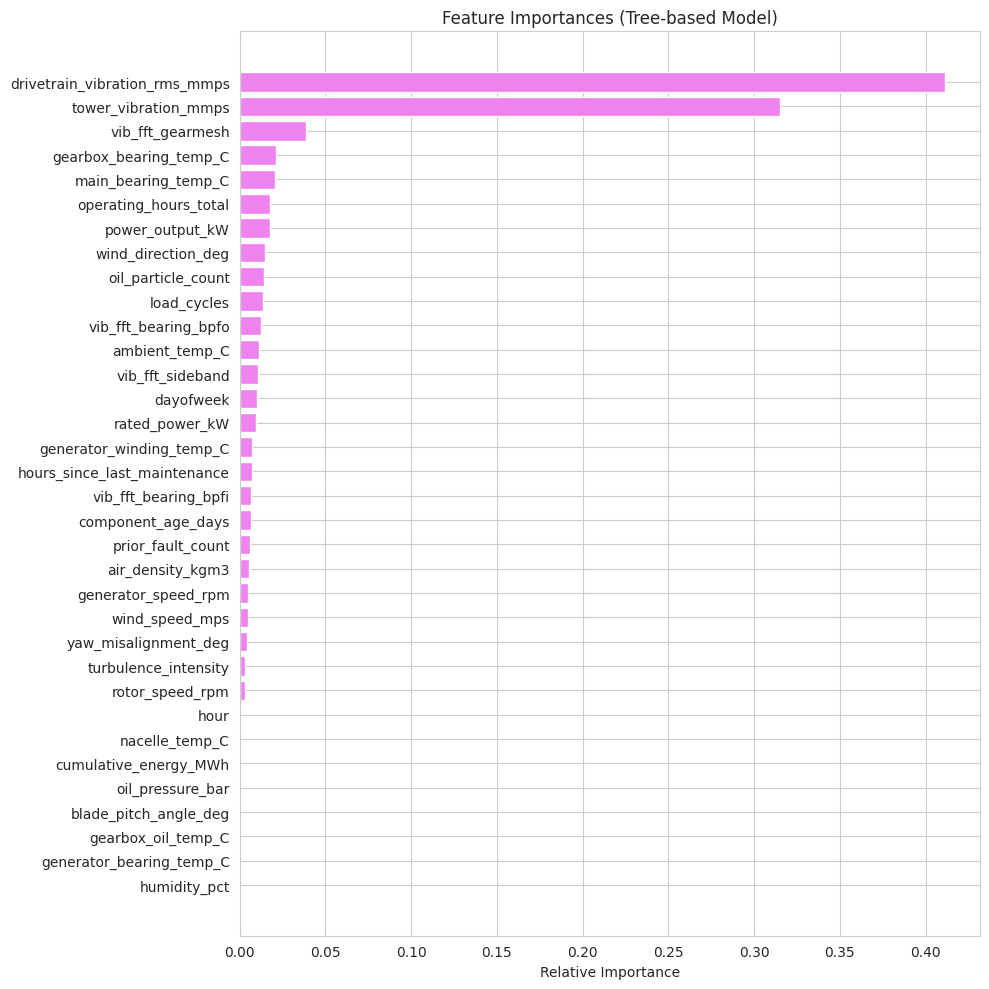

In [ ]:
# Use one of our trained models, such as tuned_xgb or tuned_gb, instead of 'best_model'
plot_feature_importances(tuned_xgb, X_train, y_train)

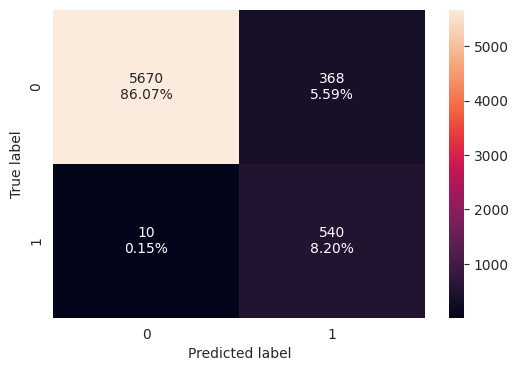

In [ ]:
plot_confusion_matrix(tuned_xgb, X_test, y_test)